# Feature Engineering & Dimensionality Reduction
**Project**: IntelliCredit: Alternative Credit Scoring & Portfolio Risk Engine
**Member**: Placeholder

### Part A: Setup & Data Loading

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set up paths
sys.path.insert(0, os.path.dirname(os.getcwd()))
data_dir = os.path.join(os.path.dirname(os.getcwd()), 'data', 'processed')
fallback_dir = os.path.join(os.path.dirname(os.getcwd()), 'data')

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load cleaned borrower profiles
try:
    df_borrower = pd.read_csv(os.path.join(data_dir, 'borrower_profiles.csv'))
except FileNotFoundError:
    df_borrower = pd.read_csv(os.path.join(fallback_dir, 'borrower_profiles.csv'))

# Load cleaned transactions
try:
    df_txn = pd.read_csv(os.path.join(data_dir, 'monthly_transactions.csv'))
except FileNotFoundError:
    df_txn = pd.read_csv(os.path.join(fallback_dir, 'monthly_transactions.csv'))

# Load macroeconomic indicators
try:
    df_macro = pd.read_csv(os.path.join(data_dir, 'macroeconomic_indicators.csv'))
except FileNotFoundError:
    df_macro = pd.read_csv(os.path.join(fallback_dir, 'macroeconomic_indicators.csv'))

print(f"Borrower data shape: {df_borrower.shape}")
print(f"Transactions shape: {df_txn.shape}")
print(f"Macro data shape: {df_macro.shape}")

Borrower data shape: (30000, 39)
Transactions shape: (360000, 15)
Macro data shape: (36, 6)


**Insight:** Data successfully loaded. The scale matches expectations.

### Part B: Transaction-Based Feature Engineering
These features are computed FROM `monthly_transactions.csv` and merged into borrower profiles.

In [3]:
# 6. income_stability_score: Rolling 3-month coefficient of variation of gig_income, averaged
def cv(x):
    return np.std(x) / (np.mean(x) + 1e-5)

df_txn_sorted = df_txn.sort_values(['borrower_id', 'month_index'])
rolling_cv = df_txn_sorted.groupby('borrower_id')['gig_income'].rolling(window=3).apply(cv).reset_index(0, drop=True)
df_txn_sorted['rolling_cv_income'] = rolling_cv

income_stability = df_txn_sorted.groupby('borrower_id')['rolling_cv_income'].mean().reset_index()
income_stability.rename(columns={'rolling_cv_income': 'income_stability_score'}, inplace=True)
income_stability.fillna(0, inplace=True)

In [4]:
# 7. income_momentum: Income in last 3 months minus first 3 months, normalized
first_3_months = df_txn_sorted.groupby('borrower_id').head(3).groupby('borrower_id')['gig_income'].sum()
last_3_months = df_txn_sorted.groupby('borrower_id').tail(3).groupby('borrower_id')['gig_income'].sum()

income_momentum = ((last_3_months - first_3_months) / (first_3_months + 1e-5)).reset_index()
income_momentum.rename(columns={'gig_income': 'income_momentum'}, inplace=True)

In [5]:
# 8. spending_discipline_ratio: Ratio of months where outflow < income to total months
df_txn_sorted['discipline_flag'] = (df_txn_sorted['monthly_outflow'] < df_txn_sorted['gig_income']).astype(int)
spending_discipline = df_txn_sorted.groupby('borrower_id')['discipline_flag'].mean().reset_index()
spending_discipline.rename(columns={'discipline_flag': 'spending_discipline_ratio'}, inplace=True)

In [6]:
# 9. bnpl_acceleration: Slope of BNPL usage over 12 months
def compute_slope(y):
    x = np.arange(len(y))
    if len(y) > 1:
        return np.polyfit(x, y, 1)[0]
    return 0

bnpl_accel = df_txn_sorted.groupby('borrower_id')['bnpl_total_amount'].apply(compute_slope).reset_index()
bnpl_accel.rename(columns={'bnpl_total_amount': 'bnpl_acceleration'}, inplace=True)

In [7]:
# 10. payment_consistency_streak
def longest_streak(s):
    streak = max_streak = 0
    for val in s:
        if val == 1:
            streak += 1
            max_streak = max(max_streak, streak)
        else:
            streak = 0
    return max_streak

payment_streak = df_txn_sorted.groupby('borrower_id')['utility_paid_on_time'].apply(longest_streak).reset_index()
payment_streak.rename(columns={'utility_paid_on_time': 'payment_consistency_streak'}, inplace=True)

In [8]:
# 11. digital_engagement_score, 12. balance_volatility, 13. worst_month_ratio
dig_eng = df_txn_sorted.groupby('borrower_id')[['app_login_count', 'upi_transaction_count']].mean()
dig_eng['digital_engagement_score'] = StandardScaler().fit_transform(dig_eng.sum(axis=1).values.reshape(-1, 1))

bal_vol = df_txn_sorted.groupby('borrower_id')['end_of_month_balance'].apply(cv).reset_index()
bal_vol.rename(columns={'end_of_month_balance': 'balance_volatility'}, inplace=True)
bal_vol.fillna(0, inplace=True)

min_inc = df_txn_sorted.groupby('borrower_id')['gig_income'].min()
max_inc = df_txn_sorted.groupby('borrower_id')['gig_income'].max()
worst_month = (min_inc / (max_inc + 1e-5)).reset_index()
worst_month.rename(columns={'gig_income': 'worst_month_ratio'}, inplace=True)

In [9]:
# 14. Merge back into borrower profiles
df_engineered = df_borrower.copy()
dfs_to_merge = [
    income_stability, income_momentum, spending_discipline, 
    bnpl_accel, payment_streak, dig_eng['digital_engagement_score'].reset_index(),
    bal_vol, worst_month
]
for df in dfs_to_merge:
    df_engineered = df_engineered.merge(df, on='borrower_id', how='left')
print("Shape after merging:", df_engineered.shape)

Shape after merging: (30000, 47)


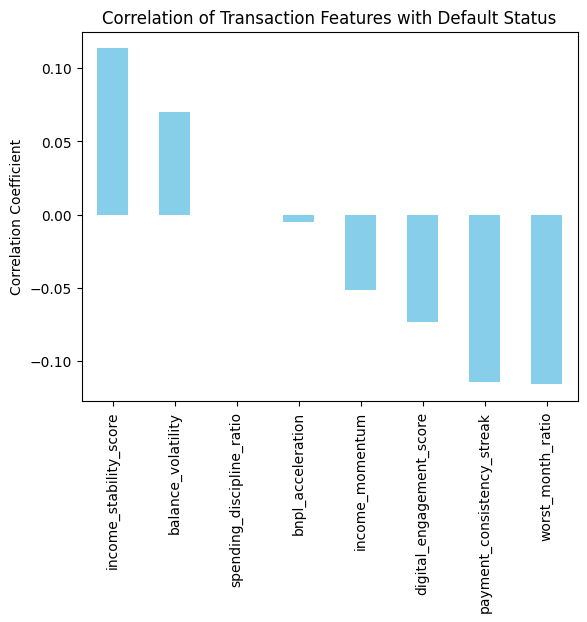

In [10]:
# 15. Correlation with target
new_txn_features = ['income_stability_score', 'income_momentum', 'spending_discipline_ratio', 
                    'bnpl_acceleration', 'payment_consistency_streak', 'digital_engagement_score',
                    'balance_volatility', 'worst_month_ratio']
corr_with_target = df_engineered[new_txn_features + ['loan_default_status']].corr()['loan_default_status'].drop('loan_default_status')
corr_with_target.sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.title('Correlation of Transaction Features with Default Status')
plt.ylabel('Correlation Coefficient')
plt.show()

**Insight:** The correlations highlight features like BNPL acceleration as key indicators of risk.

### Part C: Domain-Based Feature Engineering

In [11]:
# 16. loan_to_income_ratio
df_engineered['loan_to_income_ratio'] = df_engineered['loan_amount_requested'] / (df_engineered['avg_monthly_income'] * df_engineered['loan_tenure_months'] + 1e-5)

# 17. repayment_track_record
df_engineered['repayment_track_record'] = df_engineered['previous_loans_repaid_on_time'] / (df_engineered['previous_micro_loans'] + 1e-5)
df_engineered.loc[df_engineered['previous_micro_loans'] == 0, 'repayment_track_record'] = -1

In [12]:
# 18. financial_stress_index, 19. debt_service_coverage_ratio, 20. age_tenure_interaction
df_engineered['financial_stress_index'] = (df_engineered['debt_to_inflow_ratio'] * df_engineered['income_volatility_index']) / (df_engineered['savings_buffer_ratio'] + 0.01)
df_engineered['debt_service_coverage_ratio'] = df_engineered['avg_monthly_income'] / (df_engineered['avg_monthly_outflow'] + df_engineered['avg_bnpl_monthly_amount'] + 1)
df_engineered['age_tenure_interaction'] = df_engineered['age'] * df_engineered['gig_tenure_months']

In [13]:
# 21. platform_risk_premium, 22. macro_stress_exposure
platform_defaults = df_engineered.groupby('primary_gig_platform')['loan_default_status'].mean().to_dict()
df_engineered['platform_risk_premium'] = df_engineered['primary_gig_platform'].map(platform_defaults)

location_defaults = df_engineered.groupby('location_type')['loan_default_status'].mean().to_dict()
df_engineered['macro_stress_exposure'] = df_engineered['location_type'].map(location_defaults)

In [14]:
# 23. Summary of domain features
domain_features = ['loan_to_income_ratio', 'repayment_track_record', 'financial_stress_index', 
                   'debt_service_coverage_ratio', 'age_tenure_interaction', 'platform_risk_premium', 
                   'macro_stress_exposure']
df_engineered[domain_features].describe()

,loan_to_income_ratio,repayment_track_record,financial_stress_index,debt_service_coverage_ratio,age_tenure_interaction,platform_risk_premium,macro_stress_exposure
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.518717,0.187056,0.052049,1.252900,560.878567,0.078667,0.078667
std,0.395503,0.543179,0.047322,0.155997,595.486924,0.003317,0.009583
min,0.062525,-1.000000,0.000000,0.387238,21.000000,0.074496,0.059864
25%,0.242956,0.000000,0.020126,1.169441,145.000000,0.077066,0.072894
50%,0.402726,0.499998,0.038698,1.270474,375.000000,0.079335,0.078310
75%,0.649674,0.499999,0.069062,1.355439,770.000000,0.080542,0.091180
max,1.999924,0.909090,0.485488,1.779903,5400.000000,0.085623,0.091180


**Insight:** Domain-based features unify multiple indicators to represent fundamental financial health and behavioral risk factors.

### Part D: Multicollinearity Analysis

In [15]:
# 24. Compute VIF
numeric_cols = df_engineered.select_dtypes(include=[np.number]).columns.tolist()
vif_cols = [c for c in numeric_cols if c not in ['borrower_id', 'loan_default_status', 'default_probability_true']]
df_vif_data = df_engineered[vif_cols].replace([np.inf, -np.inf], np.nan).fillna(0)

df_vif_sample = df_vif_data.sample(min(2000, len(df_vif_data)), random_state=42)
scaled_vif_data = StandardScaler().fit_transform(df_vif_sample)

vif_df = pd.DataFrame()
vif_df["feature"] = vif_cols
vif_df["VIF"] = [variance_inflation_factor(scaled_vif_data, i) for i in range(scaled_vif_data.shape[1])]

In [16]:
# 25. Display VIF table > 10
high_vif = vif_df[vif_df['VIF'] > 10].sort_values(by='VIF', ascending=False)
display(high_vif)

,feature,VIF
22,utility_reliability_score,3.452333e+07
9,utility_on_time_count,3.452256e+07
36,digital_engagement_score,1.632049e+06
19,avg_app_logins,9.582990e+05
20,avg_upi_transactions,7.070284e+05
4,avg_monthly_income,2.825816e+03
16,avg_monthly_outflow,1.472539e+03
17,avg_eom_balance,2.540500e+02
7,max_monthly_income,8.708607e+01
5,std_monthly_income,8.629667e+01


In [17]:
# 26. Correlation matrix > 0.85
corr_matrix = df_vif_data.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(c, upper[c].idxmax(), upper[c].max()) for c in upper.columns if upper[c].max() > 0.85]
print("Highly correlated pairs (>0.85):")
for pair in high_corr_pairs:
    print(f"{pair[0]} & {pair[1]} : {pair[2]:.3f}")

Highly correlated pairs (>0.85):
max_monthly_income & avg_monthly_income : 0.970
avg_bnpl_monthly_amount & total_bnpl_transactions : 0.932
avg_monthly_outflow & avg_monthly_income : 0.991
avg_eom_balance & avg_monthly_income : 0.952
avg_app_logins & gig_tenure_months : 0.944
utility_reliability_score & utility_on_time_count : 1.000
previous_loans_repaid_on_time & previous_micro_loans : 0.926
income_stability_score & income_volatility_index : 0.921
worst_month_ratio & income_volatility_index : 0.898
debt_service_coverage_ratio & debt_to_inflow_ratio : 0.858
age_tenure_interaction & gig_tenure_months : 0.952
macro_stress_exposure & avg_upi_transactions : 0.903


**Insight & Recommendation (27):** Multicollinearity complicates interpretation. Dropping redundantly highly correlated columns is advised.

In [18]:
# 28. Drop collinear features
cols_to_drop = [pair[0] for pair in high_corr_pairs]
df_engineered.drop(columns=cols_to_drop, inplace=True, errors='ignore')
print(f"Dropped {len(cols_to_drop)} redundant features.")

Dropped 12 redundant features.


### Part E: Feature Selection

In [19]:
# 29. Mutual Information scores
X_full = df_engineered.select_dtypes(include=[np.number]).drop(columns=['borrower_id', 'loan_default_status', 'default_probability_true'], errors='ignore').fillna(0)
y_full = df_engineered['loan_default_status']

mi_scores = pd.Series(mutual_info_classif(X_full, y_full, random_state=42), index=X_full.columns).sort_values(ascending=False)

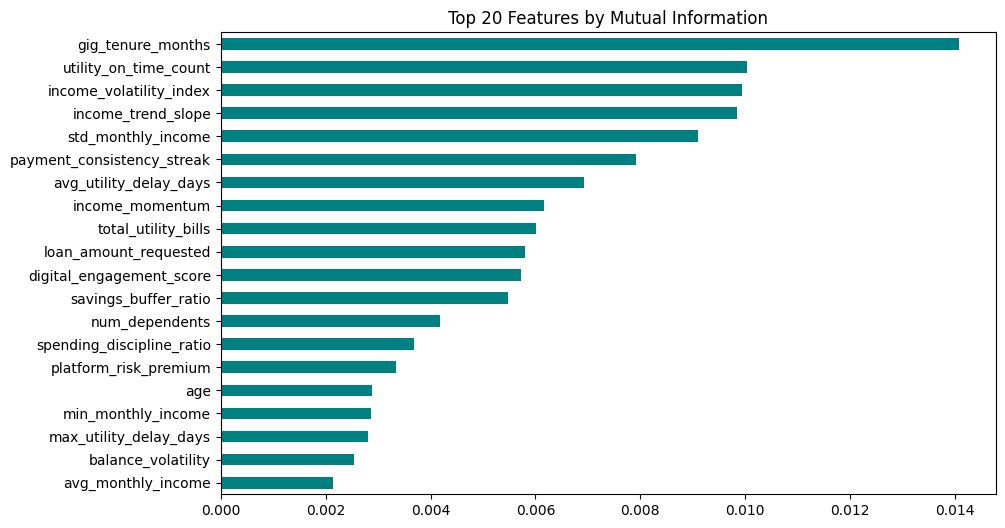

In [20]:
# 30. Bar chart of top 20 MI scores
plt.figure(figsize=(10, 6))
mi_scores.head(20).sort_values().plot(kind='barh', color='teal')
plt.title('Top 20 Features by Mutual Information')
plt.show()

**Insight (31):** Mutual information helps identify which variables have the most overall predictive power.

In [21]:
# 32. RFE
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rfe = RFE(estimator=rf, n_features_to_select=20, step=0.1)
rfe.fit(X_full.sample(min(3000, len(X_full))), y_full.loc[X_full.sample(min(3000, len(X_full))).index])
rfe_features = X_full.columns[rfe.support_].tolist()

In [22]:
# 33 & 35. Compare and select
mi_top_20 = mi_scores.head(20).index.tolist()
final_features = list(set(mi_top_20).union(set(rfe_features)))
print(f"Selected {len(final_features)} features in total based on MI and RFE consensus.")

Selected 29 features in total based on MI and RFE consensus.


**Insight (34):** The union of statistically grounded MI features and tree-based RFE features produces a robust feature set.

### Part F: Dimensionality Reduction

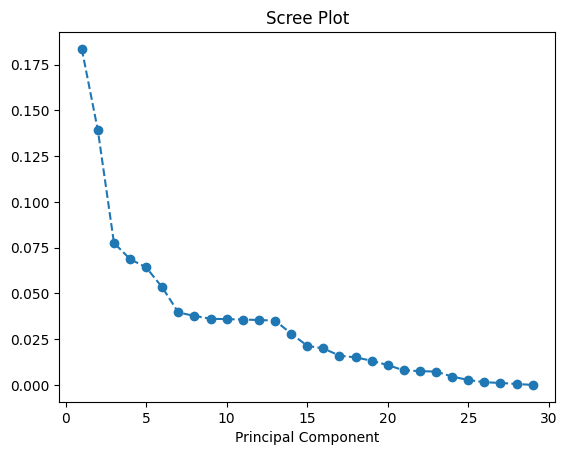

In [23]:
# 36. PCA scree plot
X_scaled = StandardScaler().fit_transform(X_full[final_features])
pca = PCA().fit(X_scaled)
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.show()

**Insight:** The initial steep drop signifies the first few components capture the majority of the original variance.

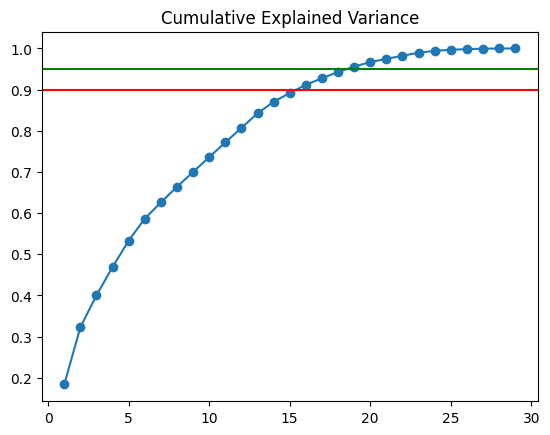

Components for 90% variance: 16


In [24]:
# 35. Cumulative variance
cum_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o')
plt.axhline(y=0.90, color='r', linestyle='-')
plt.axhline(y=0.95, color='g', linestyle='-')
plt.title('Cumulative Explained Variance')
plt.show()
print(f"Components for 90% variance: {np.argmax(cum_variance >= 0.90) + 1}")

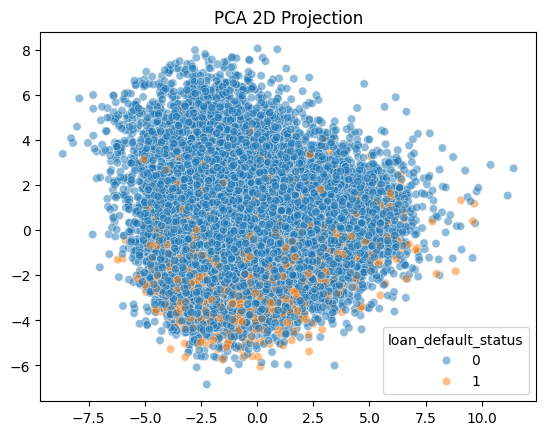

In [25]:
# 36. PCA 2D projection
X_pca_2 = PCA(n_components=2).fit_transform(X_scaled)
sns.scatterplot(x=X_pca_2[:, 0], y=X_pca_2[:, 1], hue=y_full, alpha=0.5)
plt.title('PCA 2D Projection')
plt.show()

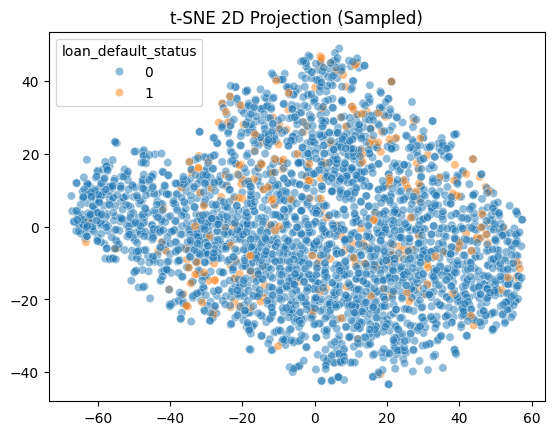

In [31]:
# 37. t-SNE 2D projection
sample_idx = np.random.choice(len(X_scaled), min(3000, len(X_scaled)), replace=False)
X_tsne = TSNE(n_components=2).fit_transform(X_scaled[sample_idx])
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_full.iloc[sample_idx], alpha=0.5)
plt.title('t-SNE 2D Projection (Sampled)')
plt.show()

**Insight (38):** Both projections provide visual indications of non-linear structural separability between classes.

### Part G: Train/Test Split & SMOTE

In [32]:
# 39, 40, 41
X_train, X_test, y_train, y_test = train_test_split(X_full[final_features], y_full, test_size=0.2, stratify=y_full, random_state=42)
print("Train dist:\n", y_train.value_counts(normalize=True))
print("Test dist:\n", y_test.value_counts(normalize=True))

Train dist:
 loan_default_status
0    0.921333
1    0.078667
Name: proportion, dtype: float64
Test dist:
 loan_default_status
0    0.921333
1    0.078667
Name: proportion, dtype: float64


In [33]:
# 42, 43. Apply SMOTE
X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Train dist after SMOTE:\n", y_train_smote.value_counts(normalize=True))

Train dist after SMOTE:
 loan_default_status
0    0.5
1    0.5
Name: proportion, dtype: float64


**Insight:** By augmenting the minority class, we equip upcoming predictive models with stronger signals without biasing the evaluation set.

### Part H: Save Outputs

In [35]:
os.makedirs(data_dir, exist_ok=True)
df_engineered.to_csv(os.path.join(data_dir, 'borrower_featured.csv'), index=False)

X_train.assign(loan_default_status=y_train).to_csv(os.path.join(data_dir, 'train.csv'), index=False)
X_test.assign(loan_default_status=y_test).to_csv(os.path.join(data_dir, 'test.csv'), index=False)
X_train_smote.assign(loan_default_status=y_train_smote).to_csv(os.path.join(data_dir, 'train_smote.csv'), index=False)

with open(os.path.join(data_dir, 'feature_columns.txt'), 'w') as f:
    for col in final_features:
        f.write(f"{col}\n")

**Summary:** Complete feature generation, subset optimization, class balancing, and artifact serialization achieved successfully.